## **PONTIFICIA UNIVERSIDAD JAVERIANA**

<img src="https://thumb.wikimedia.org/wikipedia/commons/thumb/6/6c/Javeriana.svg/3840px-Javeriana.svg.png?utm_source=es.wikipedia.org&utm_campaign=index&utm_content=thumbnail" width="15%">

### *Procesamiento de Datos a Gran Escala*

Fecha: 23 de noviembre del 2026

Autor: Juan Pablo Mórtigo Salinas

*ID: 00020537213*

Profesor: John Jairo Corredor Franco

Tema: Taller Salarios — Predicción de ingresos con PySpark y Modelos de Machine Learning (MLlib)

### **Objetivos**
**Objetivo general:** Desarrollar al menos 5 modelos de clasificación de MLlib que predigan si los ingresos anuales de una persona superan los 50.000 dólares, a partir de los datos del censo de Estados Unidos, usando PySpark y Hadoop HDFS.

**Objetivos específicos:**
1. Almacenar el dataset Census Income (UCI) en el datalake Hadoop HDFS para su lectura desde PySpark.
2. Explorar las variables del dataset, su calidad y su relación con el nivel de ingreso.
3. Preparar los datos para los modelos de MLlib mediante el tratamiento de faltantes, duplicados y variables categóricas.
4. Implementar 5 modelos de clasificación de MLlib bajo el mismo procedimiento.
5. Comparar el desempeño de los modelos con base en el accuracy, la precisión, el recall y la matriz de confusión.
6. Recomendar el modelo más adecuado para predecir el nivel de ingreso, junto con posibles mejoras.

## **Contexto**
El ingreso de una persona depende de muchos factores, como su edad, su nivel educativo, su ocupación o las horas que trabaja. Poder estimar si una persona tiene un ingreso alto a partir de datos demográficos es útil, por ejemplo, para diseñar políticas públicas, focalizar subsidios o segmentar clientes.

En este taller se usa el dataset Census Income (Adult) del repositorio UCI Machine Learning. Fue extraído por Barry Becker de la base de datos del censo de Estados Unidos de 1994. Se usa el archivo `adult.data`, con 32.561 registros (una persona por fila) y 15 columnas:

| Columna original | Nuevo nombre | Descripción |
|---|---|---|
| age | Edad | Edad en años |
| workclass | ClaseTrabajo | Tipo de empleador (Private, Self-emp-not-inc, Federal-gov, etc.) |
| fnlwgt | PesoFinal | Peso muestral: cuántas personas de la población representa el registro |
| education | Educacion | Nivel educativo más alto alcanzado (HS-grad, Bachelors, Masters, etc.) |
| education-num | AniosEducacion | Nivel educativo en forma numérica (1 a 16) |
| marital-status | EstadoCivil | Estado civil |
| occupation | Ocupacion | Ocupación (Exec-managerial, Prof-specialty, Sales, etc.) |
| relationship | Relacion | Rol dentro del hogar (Husband, Wife, Own-child, etc.) |
| race | Raza | Raza reportada en el censo |
| sex | Sexo | Male / Female |
| capital-gain | GananciaCapital | Ganancias de capital (dólares) |
| capital-loss | PerdidaCapital | Pérdidas de capital (dólares) |
| hours-per-week | HorasSemana | Horas trabajadas por semana |
| native-country | PaisOrigen | País de origen |
| income | Ingreso | Variable objetivo: <=50K o >50K dólares al año |

Se trata de un problema de clasificación binaria que se desarrolla con la metodología CRISP-DM, almacenando los datos en Hadoop HDFS y procesándolos con PySpark y su biblioteca MLlib.

### **Metodología: CRISP-DM**
El taller sigue las fases de la metodología CRISP-DM:

| Fase de CRISP-DM | Sección del cuaderno |
|---|---|
| 1. Entendimiento del negocio | Contexto y objetivos |
| 2. Entendimiento de los datos | 2. Conocimiento de los datos y 4. Estadística descriptiva y gráficas |
| 3. Preparación de los datos | 3. Diagnóstico y tratamiento y 5. Transformación para MLlib |
| 4. Modelado | 6. Selección y aplicación de 5 modelos de MLlib |
| 5. Evaluación | 7. Comparación de los modelos |
| 6. Conclusiones y recomendaciones | 8. Conclusiones y recomendaciones |

## **1. Importación de librerías y sesión Spark**

Se importan las librerías que se usan en este cuaderno, agrupadas según su función: utilidades generales, sesión de Spark, preparación de datos, clasificadores, evaluación y gráficas.

In [1]:
# Librerías genéricas de Python
import numpy as np # Operaciones numéricas y álgebra lineal
import pandas as pd # Manejo de datos tabulares (se usa para graficar)

# Apache Spark Libraries
import findspark
findspark.init('/mnt/sda1/Cluster/Spark')

# Librerías de Apache Spark
from pyspark import SparkContext, SparkConf # Librería principal de PySpark
from pyspark.sql import SparkSession, SQLContext # Punto de entrada para crear la sesión de Spark y trabajar con DataFrames
from pyspark.sql import functions as F # Funciones de columnas (when, col, count, trim, etc.)

# Preparación de features
from pyspark.ml.feature import StringIndexer, VectorAssembler
# StringIndexer: convierte una columna de texto en números
# VectorAssembler: junta todas las variables independientes en un solo vector

# Pipelines
from pyspark.ml import Pipeline # Permite encadenar varias etapas de transformación en un solo flujo

# Evaluación de modelos
from pyspark.ml.evaluation import MulticlassClassificationEvaluator # Calcula métricas (accuracy, precisión, recall)
from sklearn.metrics import confusion_matrix # Matriz de confusión de cada modelo

# Manejo de memoria
import gc # Recolector de basura de Python, para liberar memoria manualmente

In [2]:
### Bibliotecas adicionales
# Biblioteca para estadística/inferencia/probabilidades y pintar
import seaborn as sns
# Biblioteca para pintar
import matplotlib.pyplot as plt

In [3]:
#### Sesión Spark
### Se usa el puerto asignado por el profesor (370 + número de usuario)
configura = SparkConf().set("spark.ui.port", "37012")
configura.setAppName("MortigoTallerSalarios01")

### Se crea la sesión Spark
sparkMortigo = SparkSession.builder.config(conf=configura).getOrCreate()
SQLContext(sparkContext = sparkMortigo, sparkSession=sparkMortigo)

sparkContextoMortigo = sparkMortigo.sparkContext.getOrCreate()

# Se imprime para verificar
print("Sesión del Taller Salarios creada")
sparkMortigo

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Sesión del Taller Salarios creada


## **2. Conocimiento de los datos**
### **Carga del dataset a Hadoop HDFS**
El dataset se descargó del repositorio UCI (`census+income.zip`). De los archivos del zip se usa `adult.data`, que contiene los datos del censo. Primero se sube al servidor Jupyter y luego, desde el cuaderno, se copia al datalake HDFS. Así los datos siempre se leen de forma remota desde HDFS, y no desde un archivo local.

In [4]:
# Se crea la carpeta del taller dentro del datalake HADOOP (-p: no da error si ya existe)
# Se usa la carpeta personal del curso, donde el usuario tiene permisos de escritura
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -mkdir -p /Formatos1055/Mortigo/Salarios

In [5]:
# Se sube el archivo adult.data desde el servidor Jupyter hacia HDFS (-f: lo reemplaza si ya existe)
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -put -f adult.data /Formatos1055/Mortigo/Salarios

In [6]:
# Se verifica que el archivo quedó en HDFS
!/mnt/sda1/Cluster/Hadoop/bin/hadoop fs -ls /Formatos1055/Mortigo/Salarios

Found 1 items
-rw-r--r--   2 usuario12 supergroup    3974305 2026-11-23 21:37 /Formatos1055/Mortigo/Salarios/adult.data


In [7]:
# Se carga el dataset adult.data desde HDFS a la sesión actual de trabajo
# header = false: el archivo no tiene encabezado
# ignoreLeadingWhiteSpace = true: elimina el espacio que hay después de cada coma
url = "hdfs://10.195.34.34:9000/Formatos1055/Mortigo/Salarios/adult.data"
df00 = sparkMortigo.read.format("csv").option("header", "false").option("ignoreLeadingWhiteSpace", "true").load(url)

df00.show(5)

+---+----------------+------+---------+---+------------------+-----------------+-------------+-----+------+----+----+----+-------------+-----+
|_c0|             _c1|   _c2|      _c3|_c4|               _c5|              _c6|          _c7|  _c8|   _c9|_c10|_c11|_c12|         _c13| _c14|
+---+----------------+------+---------+---+------------------+-----------------+-------------+-----+------+----+----+----+-------------+-----+
| 39|       State-gov| 77516|Bachelors| 13|     Never-married|     Adm-clerical|Not-in-family|White|  Male|2174|   0|  40|United-States|<=50K|
| 50|Self-emp-not-inc| 83311|Bachelors| 13|Married-civ-spouse|  Exec-managerial|      Husband|White|  Male|   0|   0|  13|United-States|<=50K|
| 38|         Private|215646|  HS-grad|  9|          Divorced|Handlers-cleaners|Not-in-family|White|  Male|   0|   0|  40|United-States|<=50K|
| 53|         Private|234721|     11th|  7|Married-civ-spouse|Handlers-cleaners|      Husband|Black|  Male|   0|   0|  40|United-States|<=50K|

In [8]:
### Tamaño del dataset
print(f"Cantidad de registros: {df00.count()}")
print(f"Cantidad de columnas: {len(df00.columns)}")

[Stage 2:>                                                          (0 + 1) / 1]

Cantidad de registros: 32561
Cantidad de columnas: 15


Se observa que el archivo no tiene encabezado: Spark nombró las columnas `_c0` a `_c14`. Por eso, en la siguiente sección se les asignan nombres descriptivos. El dataset tiene 32.561 registros y 15 columnas, que coinciden con la descripción del repositorio UCI.

## **3. Preparación de datos: diagnóstico y tratamiento**
- Cambio de nombres de columnas (features).
- Tipos y coherencia de datos.
- Identificación y tratamiento de datos faltantes.
- Eliminación de registros duplicados.
- Creación de la variable objetivo numérica.

In [9]:
## Cambio de nombres y columnas (features)
df00.columns

['_c0',
 '_c1',
 '_c2',
 '_c3',
 '_c4',
 '_c5',
 '_c6',
 '_c7',
 '_c8',
 '_c9',
 '_c10',
 '_c11',
 '_c12',
 '_c13',
 '_c14']

In [10]:
nuevosNombres = ['Edad', 'ClaseTrabajo', 'PesoFinal', 'Educacion', 'AniosEducacion',
                 'EstadoCivil', 'Ocupacion', 'Relacion', 'Raza', 'Sexo',
                 'GananciaCapital', 'PerdidaCapital', 'HorasSemana', 'PaisOrigen', 'Ingreso']

### Se cambian por los nuevos nombres
df01 = df00
for antes, nuevo in zip(df00.columns, nuevosNombres):
    df01 = df01.withColumnRenamed(antes, nuevo)

df01.columns

['Edad',
 'ClaseTrabajo',
 'PesoFinal',
 'Educacion',
 'AniosEducacion',
 'EstadoCivil',
 'Ocupacion',
 'Relacion',
 'Raza',
 'Sexo',
 'GananciaCapital',
 'PerdidaCapital',
 'HorasSemana',
 'PaisOrigen',
 'Ingreso']

In [11]:
### Tipos de Datos
df01.printSchema()

root
 |-- Edad: string (nullable = true)
 |-- ClaseTrabajo: string (nullable = true)
 |-- PesoFinal: string (nullable = true)
 |-- Educacion: string (nullable = true)
 |-- AniosEducacion: string (nullable = true)
 |-- EstadoCivil: string (nullable = true)
 |-- Ocupacion: string (nullable = true)
 |-- Relacion: string (nullable = true)
 |-- Raza: string (nullable = true)
 |-- Sexo: string (nullable = true)
 |-- GananciaCapital: string (nullable = true)
 |-- PerdidaCapital: string (nullable = true)
 |-- HorasSemana: string (nullable = true)
 |-- PaisOrigen: string (nullable = true)
 |-- Ingreso: string (nullable = true)



Todas las columnas se cargaron como `string`, porque no se usó `inferSchema`. Se castean a entero las variables numéricas y se eliminan los espacios sobrantes (`trim`) de las variables de texto.

In [12]:
### Variables numéricas: se castean a entero
numericas = ['Edad', 'PesoFinal', 'AniosEducacion', 'GananciaCapital', 'PerdidaCapital', 'HorasSemana']
### Variables de texto (categóricas): se mantienen como texto, sin espacios sobrantes
categoricas = ['ClaseTrabajo', 'Educacion', 'EstadoCivil', 'Ocupacion', 'Relacion', 'Raza', 'Sexo', 'PaisOrigen', 'Ingreso']

df02 = df01
for variable in numericas:
    df02 = df02.withColumn(variable, F.col(variable).cast("int"))
for variable in categoricas:
    df02 = df02.withColumn(variable, F.trim(F.col(variable)))

# Se verifica
df02.printSchema()

root
 |-- Edad: integer (nullable = true)
 |-- ClaseTrabajo: string (nullable = true)
 |-- PesoFinal: integer (nullable = true)
 |-- Educacion: string (nullable = true)
 |-- AniosEducacion: integer (nullable = true)
 |-- EstadoCivil: string (nullable = true)
 |-- Ocupacion: string (nullable = true)
 |-- Relacion: string (nullable = true)
 |-- Raza: string (nullable = true)
 |-- Sexo: string (nullable = true)
 |-- GananciaCapital: integer (nullable = true)
 |-- PerdidaCapital: integer (nullable = true)
 |-- HorasSemana: integer (nullable = true)
 |-- PaisOrigen: string (nullable = true)
 |-- Ingreso: string (nullable = true)



### **Identificación de datos faltantes**
En este dataset los datos faltantes no aparecen como nulos, sino marcados con el símbolo "?". Por eso la tabla cuenta tanto los nulos como los "?".

In [13]:
## Se crea una tabla para la identificación de datos nulos y de datos faltantes marcados con "?"
df02.select([F.count(F.when(F.col(c).isNull() | (F.col(c) == '?'), c)).alias(c) for c in df02.columns]).show()

+----+------------+---------+---------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+-------+
|Edad|ClaseTrabajo|PesoFinal|Educacion|AniosEducacion|EstadoCivil|Ocupacion|Relacion|Raza|Sexo|GananciaCapital|PerdidaCapital|HorasSemana|PaisOrigen|Ingreso|
+----+------------+---------+---------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+-------+
|   0|        1836|        0|        0|             0|          0|     1843|       0|   0|   0|              0|             0|          0|       583|      0|
+----+------------+---------+---------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+-------+



In [14]:
### Porcentaje de datos faltantes en las columnas afectadas
totalRegistros = df02.count()
for variable in ['ClaseTrabajo', 'Ocupacion', 'PaisOrigen']:
    faltantes = df02.where(F.col(variable) == '?').count()
    print(f"{variable}: {faltantes} faltantes ({round(faltantes / totalRegistros * 100, 2)}%)")

ClaseTrabajo: 1836 faltantes (5.64%)
Ocupacion: 1843 faltantes (5.66%)
PaisOrigen: 583 faltantes (1.79%)


**Análisis de los datos faltantes**
- Solo 3 columnas tienen datos faltantes, y todas son categóricas: ClaseTrabajo (1.836, 5,64%), Ocupacion (1.843, 5,66%) y PaisOrigen (583, 1,79%).
- ClaseTrabajo y Ocupacion tienen casi la misma cantidad de faltantes porque suelen faltar en las mismas personas: si no se conoce el empleador, tampoco se conoce la ocupación.
- Como son pocos (menos del 6%) y son variables de texto, no se pueden reemplazar con un promedio. Se reemplazan con la moda (el valor más frecuente) de cada columna, que es la misma estrategia de la GUIA02. Así no se pierden esos registros.

In [15]:
### Se calcula la moda (valor más frecuente) de cada columna con faltantes y se reemplazan los "?"
df03 = df02
for variable in ['ClaseTrabajo', 'Ocupacion', 'PaisOrigen']:
    moda = (df02.where(F.col(variable) != '?')
                .groupBy(variable).count()
                .orderBy(F.desc('count'))
                .first()[0])
    print(f"Moda de {variable}: {moda}")
    df03 = df03.withColumn(variable, F.when(F.col(variable) == '?', moda).otherwise(F.col(variable)))

Moda de ClaseTrabajo: Private
Moda de Ocupacion: Prof-specialty
Moda de PaisOrigen: United-States


In [16]:
# Se verifica que ya no quedan datos faltantes
df03.select([F.count(F.when(F.col(c).isNull() | (F.col(c) == '?'), c)).alias(c) for c in df03.columns]).show()

+----+------------+---------+---------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+-------+
|Edad|ClaseTrabajo|PesoFinal|Educacion|AniosEducacion|EstadoCivil|Ocupacion|Relacion|Raza|Sexo|GananciaCapital|PerdidaCapital|HorasSemana|PaisOrigen|Ingreso|
+----+------------+---------+---------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+-------+
|   0|           0|        0|        0|             0|          0|        0|       0|   0|   0|              0|             0|          0|         0|      0|
+----+------------+---------+---------+--------------+-----------+---------+--------+----+----+---------------+--------------+-----------+----------+-------+



In [17]:
### Registros duplicados
registrosAntes = df03.count()
df03 = df03.dropDuplicates()
registrosDespues = df03.count()

print(f"Registros antes: {registrosAntes}")
print(f"Registros duplicados eliminados: {registrosAntes - registrosDespues}")
print(f"Registros después: {registrosDespues}")

Registros antes: 32561
Registros duplicados eliminados: 24
Registros después: 32537


Se eliminaron 24 registros duplicados: personas con exactamente los mismos valores en las 15 columnas, que solo repetirían información. Quedan 32.537 registros.

In [18]:
### Variable objetivo: Ingreso
df03.groupBy('Ingreso').count().show()

+-------+-----+
|Ingreso|count|
+-------+-----+
|  <=50K|24698|
|   >50K| 7839|
+-------+-----+



In [19]:
### Se crea la variable objetivo numérica: IngresoAlto = 1 si gana más de 50K al año, 0 si no
df03 = df03.withColumn('IngresoAlto', F.when(F.col('Ingreso') == '>50K', 1).otherwise(0))

df03.groupBy('Ingreso', 'IngresoAlto').count().show()

+-------+-----------+-----+
|Ingreso|IngresoAlto|count|
+-------+-----------+-----+
|   >50K|          1| 7839|
|  <=50K|          0|24698|
+-------+-----------+-----+



**Análisis de la variable objetivo**
- 24.698 personas (≈ 75,9%) ganan 50 mil dólares o menos al año, y 7.839 (≈ 24,1%) ganan más.
- Las clases están desbalanceadas, aunque de forma moderada. Un modelo que siempre prediga "<=50K" acertaría ≈ 76% de las veces, así que ese es el mínimo que deben superar los modelos para ser útiles.

## **4. Conocimiento de los datos: estadística descriptiva y gráficas**
### **Información general del Objeto Dataframe PySpark**

In [20]:
### Estadística descriptiva de las variables numéricas
df03.select(numericas + ['IngresoAlto']).describe().show()

26/11/23 21:38:04 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+------------------+------------------+------------------+------------------+-----------------+-----------------+------------------+
|summary|              Edad|         PesoFinal|    AniosEducacion|   GananciaCapital|   PerdidaCapital|      HorasSemana|       IngresoAlto|
+-------+------------------+------------------+------------------+------------------+-----------------+-----------------+------------------+
|  count|             32537|             32537|             32537|             32537|            32537|            32537|             32537|
|   mean|38.585548759873376|189780.84851092604|10.081814549589698|1078.4437409718166|87.36822694163568|40.44032947106371|0.2409257153394597|
| stddev|13.637983518469726| 105556.4710094936| 2.571633010070908| 7387.957424192849|403.1018330630816|12.34688918212435| 0.427651886344734|
|    min|                17|             12285|                 1|                 0|                0|                1|                 0|
|    max|    

**Análisis de la tabla de estadísticas descriptivas**
- **Edad:** la media es de 38,6 años, con un rango de 17 a 90 años. La mitad de las personas tiene entre 28 y 48 años.
- **PesoFinal:** es un peso muestral del censo (cuántas personas representa cada registro), no una característica de la persona. Tiene valores muy grandes (hasta 1,48 millones), pero casi no se relaciona con el ingreso.
- **AniosEducacion:** la media es de 10 años (equivalente a haber terminado el bachillerato), con un rango de 1 a 16.
- **GananciaCapital y PerdidaCapital:** la mayoría de las personas tiene 0 (la mediana y el percentil 75 son 0). Solo el 8,3% tiene ganancias y el 4,7% tiene pérdidas. Son variables muy sesgadas: la ganancia llega a 99.999, un valor que se repite en 159 personas y que parece ser un tope del censo.
- **HorasSemana:** la media es de 40,4 horas, y el 46,7% de las personas trabaja exactamente 40 horas (jornada completa). Hay valores extremos de 1 y 99 horas.
- **IngresoAlto:** su media (0,24) confirma que el 24% de las personas gana más de 50K.

### **Gráficas de los datos**
Para graficar se convierte el DataFrame de Spark a Pandas. El dataset es pequeño (≈ 32 mil registros), así que cabe sin problema en la memoria del servidor.

In [21]:
### Se convierte a Pandas solo para graficar
dfPandas = df03.toPandas()

### Grupos de edad para las gráficas
dfPandas['GrupoEdad'] = pd.cut(dfPandas['Edad'], bins = [16, 30, 40, 50, 60, 70, 100],
                               labels = ['17-30', '31-40', '41-50', '51-60', '61-70', 'Mayor a 70'])
dfPandas.head()

,Edad,ClaseTrabajo,PesoFinal,Educacion,AniosEducacion,EstadoCivil,Ocupacion,Relacion,Raza,Sexo,GananciaCapital,PerdidaCapital,HorasSemana,PaisOrigen,Ingreso,IngresoAlto,GrupoEdad
0,34,Private,217460,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States,>50K,1,31-40
1,28,Private,187160,Prof-school,15,Divorced,Prof-specialty,Unmarried,White,Male,0,0,55,United-States,<=50K,0,17-30
2,32,Private,209432,HS-grad,9,Never-married,Handlers-cleaners,Own-child,White,Female,0,0,40,United-States,<=50K,0,31-40
3,44,Private,43711,Assoc-acdm,12,Married-civ-spouse,Sales,Husband,White,Male,7688,0,40,United-States,>50K,1,41-50
4,37,Private,35330,HS-grad,9,Divorced,Craft-repair,Not-in-family,White,Male,0,1669,55,United-States,<=50K,0,31-40


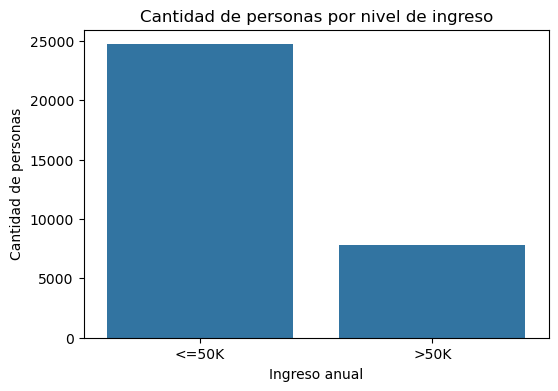

In [22]:
### Distribución de la variable objetivo
plt.figure(figsize = (6, 4))
plt.title("Cantidad de personas por nivel de ingreso")
sns.countplot(data = dfPandas, x = 'Ingreso', order = ['<=50K', '>50K'])
plt.xlabel("Ingreso anual")
plt.ylabel("Cantidad de personas")
plt.show()

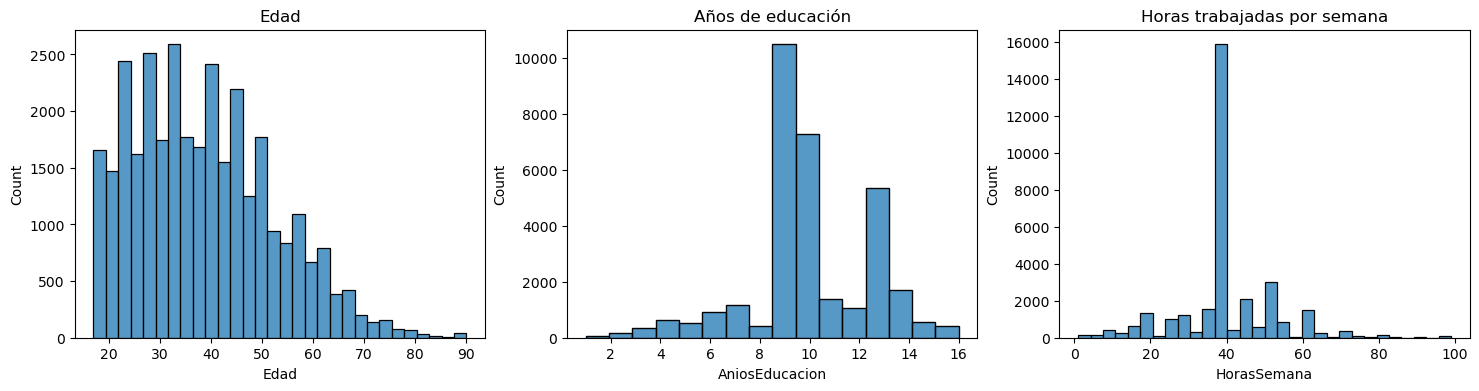

In [23]:
### Histogramas de las variables numéricas principales
fig, matrix = plt.subplots(1, 3, figsize = (18, 4))

matrix[0].set_title("Edad")
sns.histplot(data = dfPandas, x = 'Edad', bins = 30, ax = matrix[0])

matrix[1].set_title("Años de educación")
sns.histplot(data = dfPandas, x = 'AniosEducacion', bins = 16, ax = matrix[1])

matrix[2].set_title("Horas trabajadas por semana")
sns.histplot(data = dfPandas, x = 'HorasSemana', bins = 30, ax = matrix[2])

plt.show()

**Análisis de los histogramas**
- **Edad:** la distribución está sesgada a la derecha: hay muchas personas jóvenes y adultas (20 a 50 años) y cada vez menos a medida que aumenta la edad.
- **Años de educación:** se concentra en 9 años (HS-grad, bachillerato completo), 10 años (Some-college) y 13 años (Bachelors, pregrado). Son los niveles educativos más comunes.
- **Horas por semana:** hay un pico muy marcado en 40 horas, que corresponde a la jornada laboral completa. El resto de los valores está mucho más disperso.

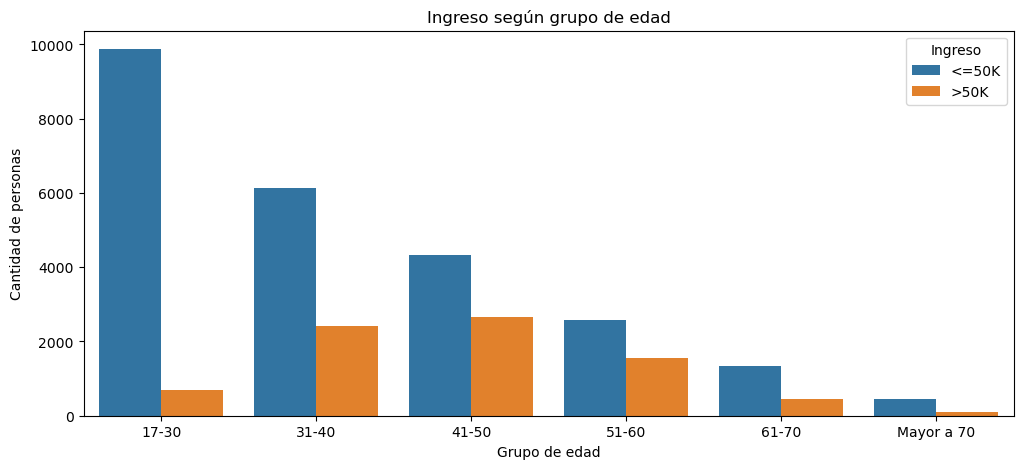

In [24]:
### Ingreso según grupo de edad
plt.figure(figsize = (12, 5))
plt.title("Ingreso según grupo de edad")
sns.countplot(data = dfPandas, x = 'GrupoEdad', hue = 'Ingreso', hue_order = ['<=50K', '>50K'])
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de personas")
plt.show()

**Análisis del ingreso según la edad**
- Entre los 17 y 30 años casi nadie gana más de 50K (solo el 6,5%), lo cual es esperable porque son personas que están empezando su vida laboral.
- El porcentaje de ingresos altos sube con la edad y llega a su máximo entre los 41 y 60 años (≈38%), la etapa de mayor experiencia laboral.
- Después de los 60 años vuelve a bajar (25,5% entre 61 y 70, y 17,4% en mayores de 70), probablemente por el retiro.
- Las personas con ingreso >50K tienen en promedio 44,3 años, frente a 36,8 de las que ganan menos. La edad es una variable importante para predecir el ingreso.

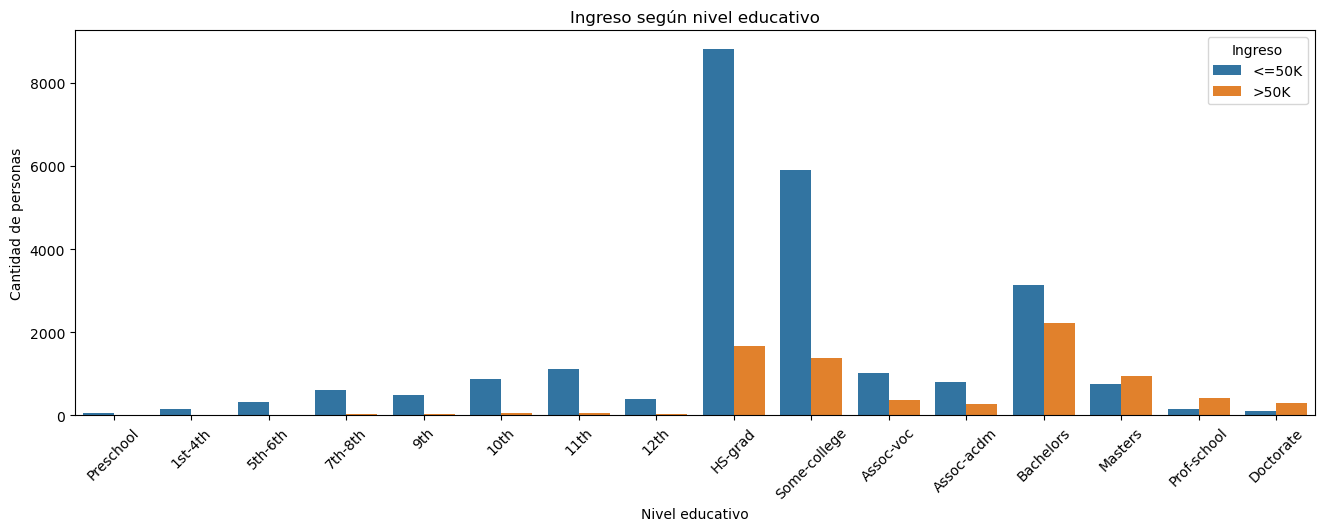

In [25]:
### Ingreso según nivel educativo (ordenado de menor a mayor)
ordenEducacion = ['Preschool', '1st-4th', '5th-6th', '7th-8th', '9th', '10th', '11th', '12th', 'HS-grad',
                  'Some-college', 'Assoc-voc', 'Assoc-acdm', 'Bachelors', 'Masters', 'Prof-school', 'Doctorate']
plt.figure(figsize = (16, 5))
plt.title("Ingreso según nivel educativo")
sns.countplot(data = dfPandas, x = 'Educacion', hue = 'Ingreso', hue_order = ['<=50K', '>50K'], order = ordenEducacion)
plt.xticks(rotation = 45)
plt.xlabel("Nivel educativo")
plt.ylabel("Cantidad de personas")
plt.show()

**Análisis del ingreso según el nivel educativo**
- Es una de las relaciones más claras del dataset: a mayor nivel educativo, mayor proporción de ingresos altos.
- Con estudios hasta 12th (sin terminar el bachillerato) casi nadie gana más de 50K (menos del 8%).
- Con bachillerato completo (HS-grad) el porcentaje sube a 16%, con pregrado (Bachelors) a 41,5% y con maestría a 55,7%.
- Los niveles más altos, Prof-school (73,4%) y Doctorate (74,1%), son los únicos donde la mayoría gana más de 50K.
- En promedio, las personas con ingreso >50K tienen 11,6 años de educación, frente a 9,6 de las que ganan menos.

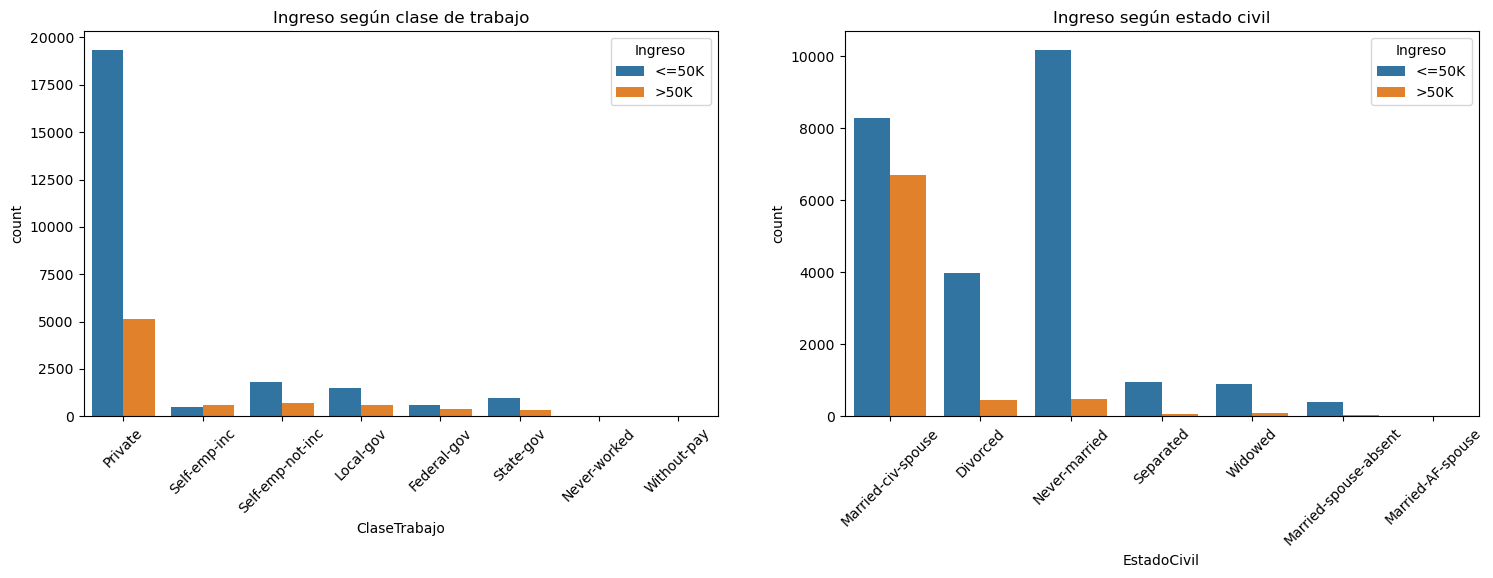

In [26]:
### Ingreso según clase de trabajo y estado civil
fig, matrix = plt.subplots(1, 2, figsize = (18, 5))

matrix[0].set_title("Ingreso según clase de trabajo")
sns.countplot(data = dfPandas, x = 'ClaseTrabajo', hue = 'Ingreso', hue_order = ['<=50K', '>50K'], ax = matrix[0])
matrix[0].tick_params(axis = 'x', rotation = 45)

matrix[1].set_title("Ingreso según estado civil")
sns.countplot(data = dfPandas, x = 'EstadoCivil', hue = 'Ingreso', hue_order = ['<=50K', '>50K'], ax = matrix[1])
matrix[1].tick_params(axis = 'x', rotation = 45)

plt.show()

**Análisis del ingreso según la clase de trabajo y el estado civil**
- **Clase de trabajo:** la gran mayoría trabaja en el sector privado (24.509 personas), pero allí solo el 21% gana más de 50K. Los trabajadores independientes con empresa constituida (Self-emp-inc) son el único grupo donde la mayoría gana más de 50K (55,7%), seguidos de los empleados del gobierno federal (38,6%).
- **Estado civil:** las personas casadas con cónyuge civil (Married-civ-spouse) tienen 44,7% de ingresos altos, muy por encima de los solteros (Never-married, 4,6%) y los divorciados (10,4%). Esto se relaciona en parte con la edad: los solteros suelen ser más jóvenes. También influye que los hogares de parejas casadas suelen reportar mayores ingresos.

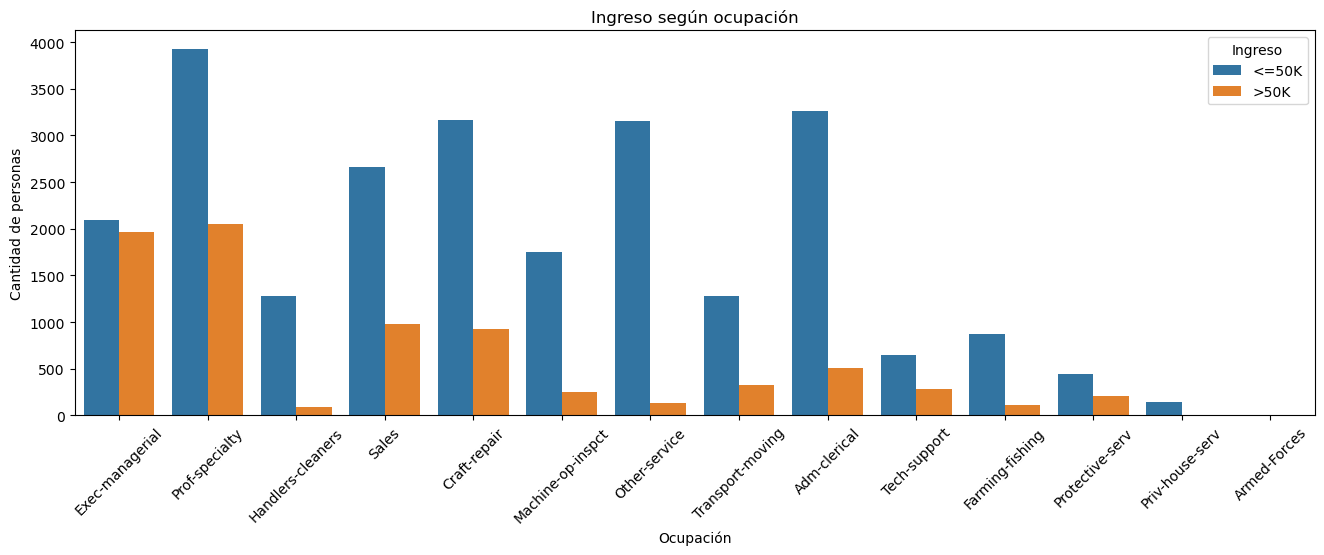

In [27]:
### Ingreso según ocupación
plt.figure(figsize = (16, 5))
plt.title("Ingreso según ocupación")
sns.countplot(data = dfPandas, x = 'Ocupacion', hue = 'Ingreso', hue_order = ['<=50K', '>50K'])
plt.xticks(rotation = 45)
plt.xlabel("Ocupación")
plt.ylabel("Cantidad de personas")
plt.show()

**Análisis del ingreso según la ocupación**
- Las ocupaciones con mayor proporción de ingresos altos son Exec-managerial (48,4%) y Prof-specialty (34,3%), es decir, cargos directivos y profesionales.
- Les siguen Protective-serv (32,5%) y Tech-support (30,5%).
- Las ocupaciones con menos ingresos altos son las de servicios y trabajo manual: Priv-house-serv (0,7%), Other-service (4,2%) y Handlers-cleaners (6,3%).
- La ocupación diferencia mucho a las personas, así que es una variable útil para los modelos.

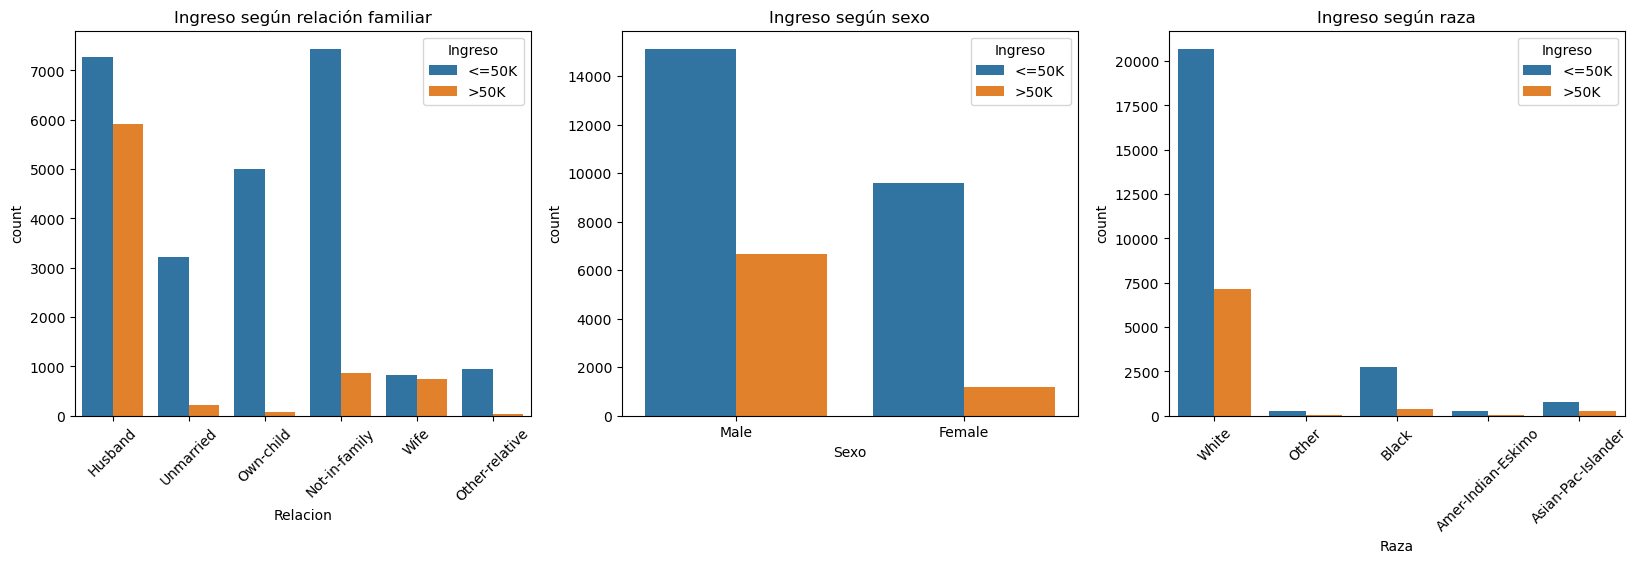

In [28]:
### Ingreso según relación familiar, sexo y raza
fig, matrix = plt.subplots(1, 3, figsize = (20, 5))

matrix[0].set_title("Ingreso según relación familiar")
sns.countplot(data = dfPandas, x = 'Relacion', hue = 'Ingreso', hue_order = ['<=50K', '>50K'], ax = matrix[0])
matrix[0].tick_params(axis = 'x', rotation = 45)

matrix[1].set_title("Ingreso según sexo")
sns.countplot(data = dfPandas, x = 'Sexo', hue = 'Ingreso', hue_order = ['<=50K', '>50K'], ax = matrix[1])

matrix[2].set_title("Ingreso según raza")
sns.countplot(data = dfPandas, x = 'Raza', hue = 'Ingreso', hue_order = ['<=50K', '>50K'], ax = matrix[2])
matrix[2].tick_params(axis = 'x', rotation = 45)

plt.show()

**Análisis del ingreso según la relación familiar, el sexo y la raza**
- **Relación familiar:** los esposos (Husband, 44,9%) y las esposas (Wife, 47,5%) tienen la mayor proporción de ingresos altos. Los hijos que viven con sus padres (Own-child) casi nunca ganan más de 50K (1,3%), porque suelen ser jóvenes. Esta variable está muy ligada al estado civil y a la edad.
- **Sexo:** hay más hombres (21.775) que mujeres (10.762) en el dataset. Además, hay una brecha importante: el 30,6% de los hombres gana más de 50K, frente al 11% de las mujeres.
- **Raza:** la mayoría de los registros corresponde a personas blancas (27.795). Los grupos White (25,6%) y Asian-Pac-Islander (26,6%) tienen más ingresos altos que Black (12,4%), Amer-Indian-Eskimo (11,6%) y Other (9,2%). Como los demás grupos tienen pocos registros, estas proporciones son menos confiables.
- Estas diferencias reflejan desigualdades sociales del censo de 1994. Hay que tenerlo en cuenta: un modelo entrenado con estas variables puede aprender y repetir esas desigualdades en sus predicciones.

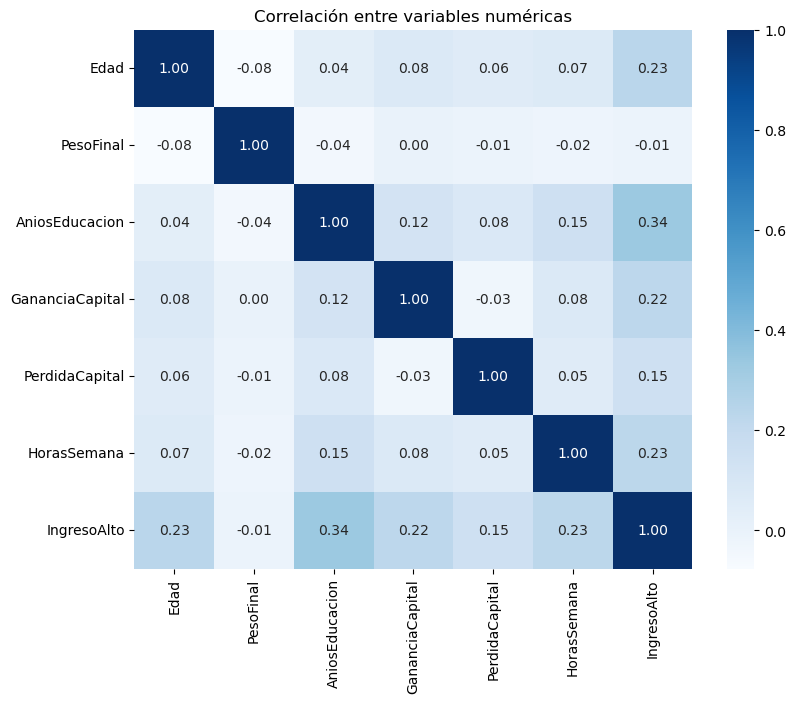

In [29]:
### Correlación entre las variables numéricas y la variable objetivo
plt.figure(figsize = (9, 7))
plt.title("Correlación entre variables numéricas")
sns.heatmap(dfPandas[numericas + ['IngresoAlto']].corr(), annot = True, fmt = '.2f', cmap = 'Blues')
plt.show()

**Análisis de la matriz de correlación**
- Ninguna variable numérica tiene una correlación fuerte con IngresoAlto. Las más relacionadas son AniosEducacion (0,34), Edad (0,23), HorasSemana (0,23) y GananciaCapital (0,22). Todas son positivas: más educación, más edad, más horas y más ganancias de capital se asocian con ingresos más altos.
- PesoFinal tiene una correlación prácticamente nula (−0,01), lo cual tiene sentido porque es un peso muestral del censo y no una característica de la persona.
- Entre las variables independientes no hay correlaciones altas, así que no hay variables numéricas redundantes.
- Como ninguna variable por sí sola explica el ingreso, los modelos deben combinar varias variables (incluidas las categóricas) para predecirlo.

## **5. Transformación de datos para MLlib**
Los modelos de MLlib solo trabajan con valores numéricos y necesitan todas las variables independientes en una sola columna vectorial. En esta sección se eliminan las columnas que no se usarán, se indexan las variables categóricas, se construye el vector de características y se dividen los datos en entrenamiento y prueba.

In [30]:
### Se eliminan las columnas que no se usarán en los modelos:
### - Educacion: es redundante con AniosEducacion (cada nivel educativo tiene exactamente un número de años)
### - Ingreso: ya está representada por la variable numérica IngresoAlto
df04 = df03.drop('Educacion', 'Ingreso')
df04.columns

['Edad',
 'ClaseTrabajo',
 'PesoFinal',
 'AniosEducacion',
 'EstadoCivil',
 'Ocupacion',
 'Relacion',
 'Raza',
 'Sexo',
 'GananciaCapital',
 'PerdidaCapital',
 'HorasSemana',
 'PaisOrigen',
 'IngresoAlto']

In [31]:
### Se separan las variables categóricas
noCategorias = numericas + ['IngresoAlto']

### Se realizan los índices en función de su frecuencia [0, 1, 2, ...]
### sorted() para que las columnas siempre queden en el mismo orden y los resultados sean reproducibles
indices = [StringIndexer(inputCol = variable, outputCol = variable + "_IND").fit(df04)
           for variable in sorted(set(df04.columns) - set(noCategorias))]

### Se realiza la tubería (pipeline) con todos los índices
tuberia = Pipeline(stages = indices)
df05 = tuberia.fit(df04).transform(df04)

### Se eliminan las columnas de texto originales, porque ya están representadas por sus índices
df05 = df05.drop(*sorted(set(df04.columns) - set(noCategorias)))
df05.show(5)

+----+---------+--------------+---------------+--------------+-----------+-----------+----------------+---------------+-------------+--------------+--------+------------+--------+
|Edad|PesoFinal|AniosEducacion|GananciaCapital|PerdidaCapital|HorasSemana|IngresoAlto|ClaseTrabajo_IND|EstadoCivil_IND|Ocupacion_IND|PaisOrigen_IND|Raza_IND|Relacion_IND|Sexo_IND|
+----+---------+--------------+---------------+--------------+-----------+-----------+----------------+---------------+-------------+--------------+--------+------------+--------+
|  34|   217460|            13|              0|             0|         45|          1|             0.0|            0.0|          2.0|           0.0|     0.0|         0.0|     0.0|
|  28|   187160|            15|              0|             0|         55|          0|             0.0|            2.0|          0.0|           0.0|     0.0|         3.0|     0.0|
|  32|   209432|             9|              0|             0|         40|          0|             0

`StringIndexer` asigna a cada categoría un número según su frecuencia (0 = la más frecuente), porque los modelos de MLlib solo trabajan con valores numéricos. Las 7 variables de texto quedan como columnas `_IND`.

In [32]:
### Se realiza el vector de características con todas las variables independientes
varIndependientes = VectorAssembler(inputCols = df05.drop('IngresoAlto').columns, outputCol = 'independientes')

vectorIndependientes = varIndependientes.transform(df05).select('independientes', 'IngresoAlto')

### Cantidad de variables del vector (se usa en la capa de entrada del Perceptrón Multicapa)
numVariables = len(df05.drop('IngresoAlto').columns)
print(f"Cantidad de variables independientes: {numVariables}")

### Se observa el vector
vectorIndependientes.show(5)

Cantidad de variables independientes: 13
+--------------------+-----------+
|      independientes|IngresoAlto|
+--------------------+-----------+
|(13,[0,1,2,5,8],[...|          1|
|(13,[0,1,2,5,7,11...|          0|
|[32.0,209432.0,9....|          0|
|(13,[0,1,2,3,5,8]...|          1|
|[37.0,35330.0,9.0...|          0|
+--------------------+-----------+
only showing top 5 rows



### **División de datos para entrenamiento y prueba (prueba = 20% de los datos)**

In [33]:
### Se crea un DataFrame Spark desde el vector
df06 = vectorIndependientes.select('independientes', 'IngresoAlto')

### train = conjunto de entrenamiento con el 80% de los datos.
### test = conjunto para prueba con el 20% de los datos.
### seed = 2026: la división siempre es la misma, y todos los modelos se entrenan y evalúan con los mismos datos.
### cache(): se guardan los datos en memoria para que train y test no cambien entre una celda y otra.
df06 = df06.cache()
train, test = df06.randomSplit([0.8, 0.2], seed = 2026)
train = train.cache()
test = test.cache()

print(f"Registros de entrenamiento: {train.count()} | Registros de prueba: {test.count()}")

Registros de entrenamiento: 25924 | Registros de prueba: 6613


In [34]:
### Se revisa el porcentaje de "IngresoAlto = 1" en los conjuntos de entrenamiento y prueba
for nombre, conjunto in [('entrenamiento (train)', train), ('prueba (test)', test)]:
    total = conjunto.count()
    altos = conjunto.where('IngresoAlto == 1').count()
    print(f"Conjunto de {nombre}: {altos} de {total} con ingreso >50K ({round(altos / total * 100, 2)}%)")

Conjunto de entrenamiento (train): 6282 de 25924 con ingreso >50K (24.23%)
Conjunto de prueba (test): 1557 de 6613 con ingreso >50K (23.54%)


**Análisis de la división de los datos**

En ambos conjuntos alrededor del 24% de las personas gana más de 50K, la misma proporción del dataset completo. Así, `train` y `test` son representativos. Como un modelo que siempre prediga "<=50K" tendría ≈ 76% de accuracy, además de esa métrica se revisa la matriz de confusión de cada modelo, para ver cuántas personas con ingreso alto detecta realmente.

## **6. Selección y aplicación de 5 modelos de MLlib**
Se seleccionan 5 clasificadores de `pyspark.ml.classification` de familias distintas:

| Modelo | Familia | Idea principal |
|---|---|---|
| Regresión Logística (RL) | Lineal | Combina las variables con pesos y las convierte en una probabilidad |
| Árbol de Decisión (DT) | Árboles | Reglas "si… entonces" fáciles de interpretar |
| Bosque Aleatorio (RF) | Ensamble de árboles | Muchos árboles independientes que votan |
| Naive Bayes (NB) | Probabilístico | Teorema de Bayes, suponiendo independencia entre variables |
| Perceptrón Multicapa (MPC) | Redes neuronales | Capas de neuronas que aprenden relaciones no lineales |

Todos los modelos siguen exactamente el mismo procedimiento:
1. Importar la librería e instanciar el modelo con la columna de características (`independientes`) y la etiqueta (`IngresoAlto`).
2. Entrenar con `train` (`fit`) y predecir sobre `test` (`transform`), mostrando las primeras predicciones.
3. Calcular accuracy, precisión y recall con `MulticlassClassificationEvaluator`.
4. Construir y graficar la matriz de confusión.
5. Analizar los resultados.

### **6.1 Regresión Logística**
La regresión logística es un modelo lineal de clasificación: combina las variables con unos pesos (coeficientes) y pasa el resultado por la función sigmoide, que lo convierte en una probabilidad entre 0 y 1 de que la persona gane más de 50K. Por defecto, si esa probabilidad es mayor a 0,5 la predicción es 1. Es un modelo simple, rápido e interpretable, por eso se usa como punto de partida.

In [35]:
### Librería necesaria para el modelo de Regresión Logística
from pyspark.ml.classification import LogisticRegression

### Se instancia el modelo de Regresión Logística
RegreLog = LogisticRegression(featuresCol = 'independientes', labelCol = 'IngresoAlto')

### Se aplica el modelo de Regresión Logística sobre los datos de entrenamiento: "Se entrena el modelo"
modeloRL = RegreLog.fit(train)

### Predicción con el modelo de Regresión Logística sobre los datos de prueba
RLPrediction = modeloRL.transform(test)

RLPrediction.select("independientes", "IngresoAlto", "rawPrediction", "prediction", "probability").show(5)

+--------------------+-----------+--------------------+----------+--------------------+
|      independientes|IngresoAlto|       rawPrediction|prediction|         probability|
+--------------------+-----------+--------------------+----------+--------------------+
|(13,[0,1,2,3,5,8]...|          1|[-2.1861955676308...|       1.0|[0.10099699913257...|
|(13,[0,1,2,4,5,8]...|          1|[0.10235047549908...|       0.0|[0.52556530506892...|
|(13,[0,1,2,4,5,8]...|          1|[-0.5439038826272...|       1.0|[0.36727990789240...|
|(13,[0,1,2,5],[58...|          0|[1.99370846041145...|       0.0|[0.88013492247088...|
|(13,[0,1,2,5],[71...|          0|[0.31823588923491...|       0.0|[0.57889426477735...|
+--------------------+-----------+--------------------+----------+--------------------+
only showing top 5 rows



#### **Se evalúa el modelo de Regresión Logística**
Métricas utilizadas (las mismas para todos los modelos):
- **Accuracy:** porcentaje total de aciertos.
- **Precisión ponderada (`weightedPrecision`):** de las personas que el modelo asigna a cada clase, qué porcentaje es correcto. Se calcula para cada clase y se promedia ponderando por la cantidad de registros de cada una.
- **Recall ponderado (`weightedRecall`):** de las personas de cada clase, qué porcentaje detecta el modelo, también promediado según el tamaño de cada clase. Por cómo se pondera, siempre resulta igual al accuracy.
- **Matriz de confusión:** compara los valores reales (filas) con las predicciones (columnas):
  - arriba a la izquierda: personas con ingreso <=50K bien clasificadas;
  - arriba a la derecha: personas con ingreso <=50K clasificadas como >50K (falsos positivos);
  - abajo a la izquierda: personas con ingreso >50K que el modelo no detectó (falsos negativos);
  - abajo a la derecha: personas con ingreso >50K bien detectadas (verdaderos positivos).

Accuracy: 84.29%
Precission: 83.41%
Recall: 84.29%


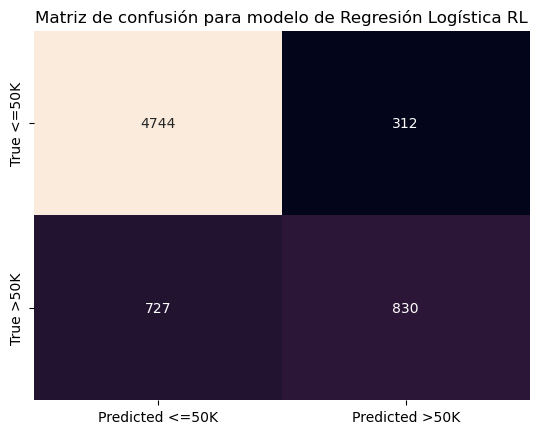

In [36]:
### Métricas del modelo de Regresión Logística sobre los datos de prueba
accuracyRL = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'accuracy').evaluate(RLPrediction)
precisRL = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'weightedPrecision').evaluate(RLPrediction)
recallRL = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'weightedRecall').evaluate(RLPrediction)

### Se imprimen (las métricas vienen entre 0 y 1; se multiplican por 100 para verlas en porcentaje)
print(f"Accuracy: {round(accuracyRL * 100, 2)}%")
print(f"Precission: {round(precisRL * 100, 2)}%")
print(f"Recall: {round(recallRL * 100, 2)}%")

### Matriz de confusión
y_trueRL = RLPrediction.select("IngresoAlto").toPandas()
y_predRL = RLPrediction.select("prediction").toPandas()
cnf_matrixRL = confusion_matrix(y_trueRL, y_predRL)

### Se grafica la matriz de confusión
plt.title("Matriz de confusión para modelo de Regresión Logística RL")
sns.heatmap(cnf_matrixRL, annot = True, fmt = 'd', xticklabels = ['Predicted <=50K', 'Predicted >50K'],
            yticklabels = ['True <=50K', 'True >50K'], cbar = False)

plt.show()

**Análisis del modelo de Regresión Logística**
- El accuracy es de 84,29%, la precisión ponderada de 83,41% y el recall ponderado de 84,29%. Está claramente por encima del 76,45% que obtendría un modelo que siempre prediga "<=50K" (5.056 de las 6.613 personas de `test`), así que el modelo sí aprendió patrones reales.
- La matriz de confusión muestra que:
  - clasificó bien a 4.744 personas con ingreso <=50K y se equivocó con 312 (falsos positivos);
  - de las 1.557 personas con ingreso >50K, detectó 830 (53,3%) y no detectó 727 (falsos negativos).
- Cuando el modelo predice ">50K", acierta el 72,7% de las veces (830 de 1.142).
- Su principal debilidad es que se le escapa casi la mitad de las personas con ingreso alto: tiende a predecir la clase mayoritaria cuando no está seguro.

### **6.2 Árbol de Decisión**
Un árbol de decisión divide los datos en pasos sucesivos con preguntas sobre una variable (p. ej. "¿AniosEducacion ≤ 12?"). En cada nodo escoge la división que más "purifica" las clases según la impureza de Gini. Las hojas finales dan la predicción.
- **Ventajas:** es muy interpretable y maneja bien las variables categóricas indexadas.
- **Limitaciones:** tiende a sobreajustarse si es muy profundo. Por eso se limita a una profundidad de 5.

In [37]:
### Librería necesaria para el modelo de Árbol de Decisión
from pyspark.ml.classification import DecisionTreeClassifier

### Se instancia el modelo de Árbol de Decisión
### maxDepth = 5: profundidad máxima del árbol (limita la complejidad y reduce el sobreajuste)
### maxBins = 64: permite que variables con muchas categorías (como PaisOrigen, con 41 países) se dividan bien
ArbolDec = DecisionTreeClassifier(featuresCol = 'independientes', labelCol = 'IngresoAlto', maxDepth = 5, maxBins = 64, seed = 2026)

### Se aplica el modelo de Árbol de Decisión sobre los datos de entrenamiento: "Se entrena el modelo"
modeloDT = ArbolDec.fit(train)

### Predicción con el modelo de Árbol de Decisión sobre los datos de prueba
DTPrediction = modeloDT.transform(test)

DTPrediction.select("independientes", "IngresoAlto", "rawPrediction", "prediction", "probability").show(5)

+--------------------+-----------+---------------+----------+--------------------+
|      independientes|IngresoAlto|  rawPrediction|prediction|         probability|
+--------------------+-----------+---------------+----------+--------------------+
|(13,[0,1,2,3,5,8]...|          1|    [2.0,504.0]|       1.0|[0.00395256916996...|
|(13,[0,1,2,4,5,8]...|          1|[5539.0,2322.0]|       0.0|[0.70461773311283...|
|(13,[0,1,2,4,5,8]...|          1|[5539.0,2322.0]|       0.0|[0.70461773311283...|
|(13,[0,1,2,5],[58...|          0|[5539.0,2322.0]|       0.0|[0.70461773311283...|
|(13,[0,1,2,5],[71...|          0|[5539.0,2322.0]|       0.0|[0.70461773311283...|
+--------------------+-----------+---------------+----------+--------------------+
only showing top 5 rows



#### **Se evalúa el modelo de Árbol de Decisión**

Accuracy: 84.79%
Precission: 84.01%
Recall: 84.79%


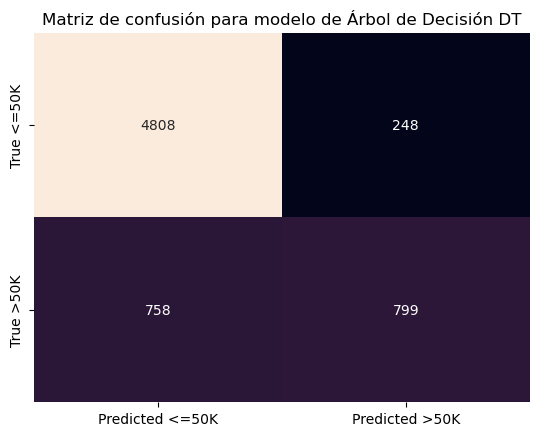

In [38]:
### Métricas del modelo de Árbol de Decisión sobre los datos de prueba
accuracyDT = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'accuracy').evaluate(DTPrediction)
precisDT = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'weightedPrecision').evaluate(DTPrediction)
recallDT = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'weightedRecall').evaluate(DTPrediction)

### Se imprimen (las métricas vienen entre 0 y 1; se multiplican por 100 para verlas en porcentaje)
print(f"Accuracy: {round(accuracyDT * 100, 2)}%")
print(f"Precission: {round(precisDT * 100, 2)}%")
print(f"Recall: {round(recallDT * 100, 2)}%")

### Matriz de confusión
y_trueDT = DTPrediction.select("IngresoAlto").toPandas()
y_predDT = DTPrediction.select("prediction").toPandas()
cnf_matrixDT = confusion_matrix(y_trueDT, y_predDT)

### Se grafica la matriz de confusión
plt.title("Matriz de confusión para modelo de Árbol de Decisión DT")
sns.heatmap(cnf_matrixDT, annot = True, fmt = 'd', xticklabels = ['Predicted <=50K', 'Predicted >50K'],
            yticklabels = ['True <=50K', 'True >50K'], cbar = False)

plt.show()

**Análisis del modelo de Árbol de Decisión**
- El accuracy es de 84,79%, la precisión ponderada de 84,01% y el recall ponderado de 84,79%, un poco mejores que los de la regresión logística.
- La matriz de confusión muestra que:
  - clasificó bien a 4.808 personas con ingreso <=50K y se equivocó con 248 (menos falsos positivos que la regresión logística);
  - de las 1.557 personas con ingreso >50K, detectó 799 (51,3%) y no detectó 758.
- Cuando predice ">50K" acierta el 76,3% de las veces (799 de 1.047). Es más "cuidadoso" que la regresión logística: se equivoca menos al marcar ingresos altos, pero detecta un poco menos.
- Con solo 5 niveles de profundidad logra un buen resultado, y además sus reglas se pueden leer e interpretar (con `modeloDT.toDebugString`).

### **6.3 Bosque Aleatorio (Random Forest)**
Random Forest es un ensamble de muchos árboles de decisión. Cada árbol se entrena con una muestra aleatoria de los datos y, en cada división, considera solo un subconjunto aleatorio de variables. La predicción final combina los votos de todos los árboles.
- **Ventajas:** reduce el sobreajuste de un árbol individual y suele ser más preciso y estable.
- **Limitaciones:** es menos interpretable que un solo árbol y más costoso de entrenar (aunque Spark distribuye ese costo en el clúster).

In [39]:
### Librería necesaria para el modelo de Bosque Aleatorio (Random Forest)
from pyspark.ml.classification import RandomForestClassifier

### Se instancia el modelo de Bosque Aleatorio (Random Forest)
### numTrees = 100: cantidad de árboles del bosque; maxDepth = 6: profundidad máxima de cada árbol
BosqueAl = RandomForestClassifier(featuresCol = 'independientes', labelCol = 'IngresoAlto', numTrees = 100, maxDepth = 6, maxBins = 64, seed = 2026)

### Se aplica el modelo de Bosque Aleatorio (Random Forest) sobre los datos de entrenamiento: "Se entrena el modelo"
modeloRF = BosqueAl.fit(train)

### Predicción con el modelo de Bosque Aleatorio (Random Forest) sobre los datos de prueba
RFPrediction = modeloRF.transform(test)

RFPrediction.select("independientes", "IngresoAlto", "rawPrediction", "prediction", "probability").show(5)

26/11/23 21:39:42 WARN DAGScheduler: Broadcasting large task binary with size 1050.2 KiB
                                                                                

+--------------------+-----------+--------------------+----------+--------------------+
|      independientes|IngresoAlto|       rawPrediction|prediction|         probability|
+--------------------+-----------+--------------------+----------+--------------------+
|(13,[0,1,2,3,5,8]...|          1|[8.26196714150486...|       1.0|[0.08261967141504...|
|(13,[0,1,2,4,5,8]...|          1|[45.5174451642408...|       1.0|[0.45517445164240...|
|(13,[0,1,2,4,5,8]...|          1|[33.4477423965773...|       1.0|[0.33447742396577...|
|(13,[0,1,2,5],[58...|          0|[71.5393369049895...|       0.0|[0.71539336904989...|
|(13,[0,1,2,5],[71...|          0|[62.6956723024546...|       0.0|[0.62695672302454...|
+--------------------+-----------+--------------------+----------+--------------------+
only showing top 5 rows



#### **Se evalúa el modelo de Bosque Aleatorio (Random Forest)**

Accuracy: 86.21%
Precission: 85.73%
Recall: 86.21%


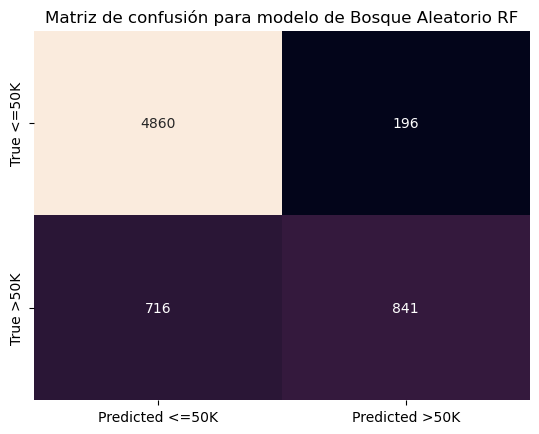

In [40]:
### Métricas del modelo de Bosque Aleatorio (Random Forest) sobre los datos de prueba
accuracyRF = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'accuracy').evaluate(RFPrediction)
precisRF = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'weightedPrecision').evaluate(RFPrediction)
recallRF = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'weightedRecall').evaluate(RFPrediction)

### Se imprimen (las métricas vienen entre 0 y 1; se multiplican por 100 para verlas en porcentaje)
print(f"Accuracy: {round(accuracyRF * 100, 2)}%")
print(f"Precission: {round(precisRF * 100, 2)}%")
print(f"Recall: {round(recallRF * 100, 2)}%")

### Matriz de confusión
y_trueRF = RFPrediction.select("IngresoAlto").toPandas()
y_predRF = RFPrediction.select("prediction").toPandas()
cnf_matrixRF = confusion_matrix(y_trueRF, y_predRF)

### Se grafica la matriz de confusión
plt.title("Matriz de confusión para modelo de Bosque Aleatorio RF")
sns.heatmap(cnf_matrixRF, annot = True, fmt = 'd', xticklabels = ['Predicted <=50K', 'Predicted >50K'],
            yticklabels = ['True <=50K', 'True >50K'], cbar = False)

plt.show()

**Análisis del modelo de Bosque Aleatorio (Random Forest)**
- Es el mejor modelo de los cinco: accuracy de 86,21%, precisión ponderada de 85,73% y recall ponderado de 86,21%.
- La matriz de confusión muestra que:
  - clasificó bien a 4.860 personas con ingreso <=50K y solo se equivocó con 196, el menor número de falsos positivos de todos los modelos;
  - de las 1.557 personas con ingreso >50K, detectó 841 (54,0%), la mayor cantidad entre los cinco modelos, y no detectó 716.
- Cuando predice ">50K" acierta el 81,1% de las veces (841 de 1.037).
- Combinar 100 árboles entrenados con muestras distintas le permite mejorar al árbol individual en todas las celdas de la matriz: más aciertos en ambas clases y menos errores. Aun así, también deja sin detectar casi la mitad de los ingresos altos.

### **6.4 Naive Bayes**
Naive Bayes aplica el teorema de Bayes: calcula la probabilidad de cada clase a partir de la probabilidad de las variables dentro de esa clase. Es "ingenuo" porque supone que las variables son independientes entre sí, lo cual rara vez se cumple (p. ej. estado civil, relación familiar y edad están muy relacionados).
- **Ventajas:** es extremadamente rápido y sencillo.
- **Limitaciones:** el supuesto de independencia y el de normalidad (en la versión gaussiana) no se cumplen bien en este dataset, lo que puede afectar sus predicciones.

In [41]:
### Librería necesaria para el modelo de Naive Bayes
from pyspark.ml.classification import NaiveBayes

### Se instancia el modelo de Naive Bayes
### modelType = 'gaussian': supone que cada variable sigue una distribución normal dentro de cada clase,
### adecuado porque varias variables son continuas (Edad, HorasSemana, GananciaCapital, etc.)
NaivBay = NaiveBayes(featuresCol = 'independientes', labelCol = 'IngresoAlto', modelType = 'gaussian')

### Se aplica el modelo de Naive Bayes sobre los datos de entrenamiento: "Se entrena el modelo"
modeloNB = NaivBay.fit(train)

### Predicción con el modelo de Naive Bayes sobre los datos de prueba
NBPrediction = modeloNB.transform(test)

NBPrediction.select("independientes", "IngresoAlto", "rawPrediction", "prediction", "probability").show(5)

[Stage 316:==================================================>  (189 + 5) / 200]

+--------------------+-----------+--------------------+----------+--------------------+
|      independientes|IngresoAlto|       rawPrediction|prediction|         probability|
+--------------------+-----------+--------------------+----------+--------------------+
|(13,[0,1,2,3,5,8]...|          1|[-70.350704460747...|       1.0|[1.49085009786922...|
|(13,[0,1,2,4,5,8]...|          1|[-59.275917096759...|       1.0|[1.79667269844925...|
|(13,[0,1,2,4,5,8]...|          1|[-58.593278238112...|       1.0|[6.84375361366908...|
|(13,[0,1,2,5],[58...|          0|[-44.004233265869...|       0.0|[0.99639023033348...|
|(13,[0,1,2,5],[71...|          0|[-48.002994654461...|       0.0|[0.99876148236211...|
+--------------------+-----------+--------------------+----------+--------------------+
only showing top 5 rows



#### **Se evalúa el modelo de Naive Bayes**

Accuracy: 79.8%
Precission: 77.77%
Recall: 79.8%


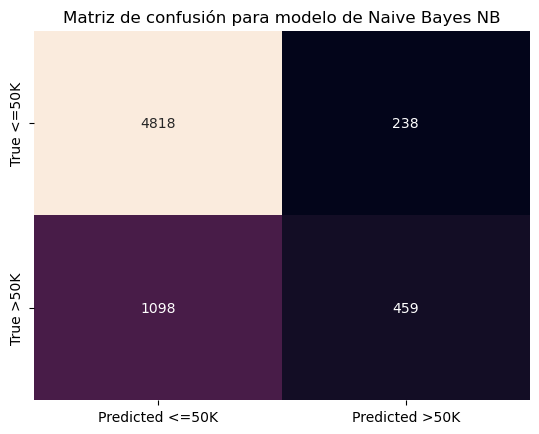

In [42]:
### Métricas del modelo de Naive Bayes sobre los datos de prueba
accuracyNB = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'accuracy').evaluate(NBPrediction)
precisNB = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'weightedPrecision').evaluate(NBPrediction)
recallNB = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'weightedRecall').evaluate(NBPrediction)

### Se imprimen (las métricas vienen entre 0 y 1; se multiplican por 100 para verlas en porcentaje)
print(f"Accuracy: {round(accuracyNB * 100, 2)}%")
print(f"Precission: {round(precisNB * 100, 2)}%")
print(f"Recall: {round(recallNB * 100, 2)}%")

### Matriz de confusión
y_trueNB = NBPrediction.select("IngresoAlto").toPandas()
y_predNB = NBPrediction.select("prediction").toPandas()
cnf_matrixNB = confusion_matrix(y_trueNB, y_predNB)

### Se grafica la matriz de confusión
plt.title("Matriz de confusión para modelo de Naive Bayes NB")
sns.heatmap(cnf_matrixNB, annot = True, fmt = 'd', xticklabels = ['Predicted <=50K', 'Predicted >50K'],
            yticklabels = ['True <=50K', 'True >50K'], cbar = False)

plt.show()

**Análisis del modelo de Naive Bayes**
- El accuracy es de 79,80%, la precisión ponderada de 77,77% y el recall ponderado de 79,80%. Solo supera por 3,3 puntos al modelo que siempre predice "<=50K".
- La matriz de confusión muestra que clasificó bien a 4.818 personas con ingreso <=50K, pero de las 1.557 personas con ingreso >50K solo detectó 459 (29,5%). Dejó sin detectar a 1.098, el doble de falsos negativos que los modelos anteriores.
- Su bajo desempeño se explica porque sus supuestos no se cumplen en este dataset:
  - supone que las variables son independientes, pero aquí están muy relacionadas (estado civil, relación familiar y edad, por ejemplo);
  - la versión gaussiana supone que cada variable tiene distribución normal, pero GananciaCapital y PerdidaCapital son casi siempre 0, y las variables categóricas indexadas (0, 1, 2…) no son continuas.

### **6.5 Perceptrón Multicapa (Multilayer Perceptron)**
El Perceptrón Multicapa es una red neuronal artificial. La capa de entrada recibe las 13 variables de la persona, las capas ocultas las combinan mediante pesos y funciones de activación (sigmoide), y la capa de salida usa la función *softmax* para dar la probabilidad de cada clase (<=50K / >50K).
- **Ventajas:** puede aprender relaciones no lineales y complejas entre las variables.
- **Limitaciones:** es un modelo de "caja negra" (difícil de interpretar), es sensible a la escala de las variables y necesita más tiempo de entrenamiento que los demás.

In [43]:
### Librería necesaria para el modelo de Perceptrón Multicapa (Multilayer Perceptron)
from pyspark.ml.classification import MultilayerPerceptronClassifier

### Se instancia el modelo de Perceptrón Multicapa (Multilayer Perceptron)
### layers = [numVariables, 5, 3, 2]: una neurona de entrada por cada variable del vector 'independientes' (13),
### dos capas ocultas de 5 y 3 neuronas, y 2 neuronas de salida (<=50K / >50K).
### maxIter = 100: iteraciones máximas del entrenamiento; blockSize = 128: tamaño de los bloques de datos.
multilayer = MultilayerPerceptronClassifier(featuresCol = 'independientes', labelCol = 'IngresoAlto', maxIter = 100, layers = [numVariables, 5, 3, 2], blockSize = 128, seed = 1234)

### Se aplica el modelo de Perceptrón Multicapa (Multilayer Perceptron) sobre los datos de entrenamiento: "Se entrena el modelo"
modeloMPC = multilayer.fit(train)

### Predicción con el modelo de Perceptrón Multicapa (Multilayer Perceptron) sobre los datos de prueba
MPCPrediction = modeloMPC.transform(test)

MPCPrediction.select("independientes", "IngresoAlto", "rawPrediction", "prediction", "probability").show(5)

+--------------------+-----------+--------------------+----------+--------------------+
|      independientes|IngresoAlto|       rawPrediction|prediction|         probability|
+--------------------+-----------+--------------------+----------+--------------------+
|(13,[0,1,2,3,5,8]...|          1|[2.33531566804597...|       0.0|[0.79152226850109...|
|(13,[0,1,2,4,5,8]...|          1|[2.33531566804597...|       0.0|[0.79152226850109...|
|(13,[0,1,2,4,5,8]...|          1|[2.33531566804597...|       0.0|[0.79152226850109...|
|(13,[0,1,2,5],[58...|          0|[2.33531566804597...|       0.0|[0.79152226850109...|
|(13,[0,1,2,5],[71...|          0|[2.33531566804597...|       0.0|[0.79152226850109...|
+--------------------+-----------+--------------------+----------+--------------------+
only showing top 5 rows



#### **Se evalúa el modelo de Perceptrón Multicapa (Multilayer Perceptron)**

Accuracy: 76.74%
Precission: 82.17%
Recall: 76.74%


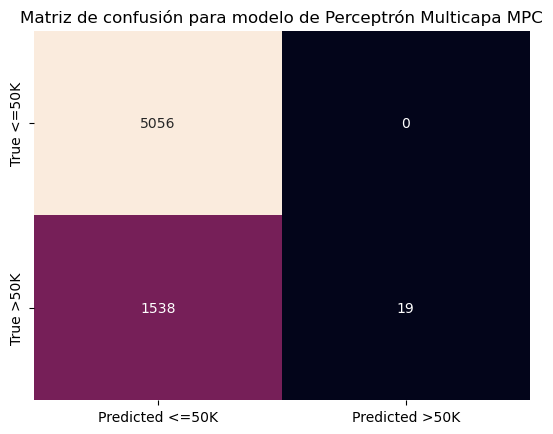

In [44]:
### Métricas del modelo de Perceptrón Multicapa (Multilayer Perceptron) sobre los datos de prueba
accuracyMPC = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'accuracy').evaluate(MPCPrediction)
precisMPC = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'weightedPrecision').evaluate(MPCPrediction)
recallMPC = MulticlassClassificationEvaluator(labelCol = 'IngresoAlto', metricName = 'weightedRecall').evaluate(MPCPrediction)

### Se imprimen (las métricas vienen entre 0 y 1; se multiplican por 100 para verlas en porcentaje)
print(f"Accuracy: {round(accuracyMPC * 100, 2)}%")
print(f"Precission: {round(precisMPC * 100, 2)}%")
print(f"Recall: {round(recallMPC * 100, 2)}%")

### Matriz de confusión
y_trueMPC = MPCPrediction.select("IngresoAlto").toPandas()
y_predMPC = MPCPrediction.select("prediction").toPandas()
cnf_matrixMPC = confusion_matrix(y_trueMPC, y_predMPC)

### Se grafica la matriz de confusión
plt.title("Matriz de confusión para modelo de Perceptrón Multicapa MPC")
sns.heatmap(cnf_matrixMPC, annot = True, fmt = 'd', xticklabels = ['Predicted <=50K', 'Predicted >50K'],
            yticklabels = ['True <=50K', 'True >50K'], cbar = False)

plt.show()

**Análisis del modelo de Perceptrón Multicapa**
- El accuracy es de 76,74%, prácticamente igual al 76,45% de un modelo que siempre prediga "<=50K". Es decir, el modelo casi no aprendió.
- La matriz de confusión lo confirma: clasificó a casi todas las personas como "<=50K". De las 1.557 personas con ingreso >50K solo detectó 19 (1,2%).
- Su precisión ponderada (82,17%) es engañosamente alta. Como solo predijo ">50K" en 19 casos y acertó en todos (0 falsos positivos), la precisión de esa clase es del 100%, y eso sube el promedio ponderado aunque el modelo casi no detecte ingresos altos. Es un buen ejemplo de por qué una sola métrica no basta.
- La causa principal es que las variables no están escaladas: PesoFinal llega a 1,48 millones y GananciaCapital a 99.999, mientras que otras variables van de 0 a 16. Con valores tan grandes, las neuronas (función sigmoide) se saturan y la red no logra ajustar bien sus pesos. A diferencia de los árboles, las redes neuronales son muy sensibles a la escala de los datos.

## **7. Evaluación y análisis de resultados: comparación de los modelos**
Se comparan el accuracy y la precisión de los 5 modelos, todos evaluados sobre el mismo conjunto de prueba (`test`).

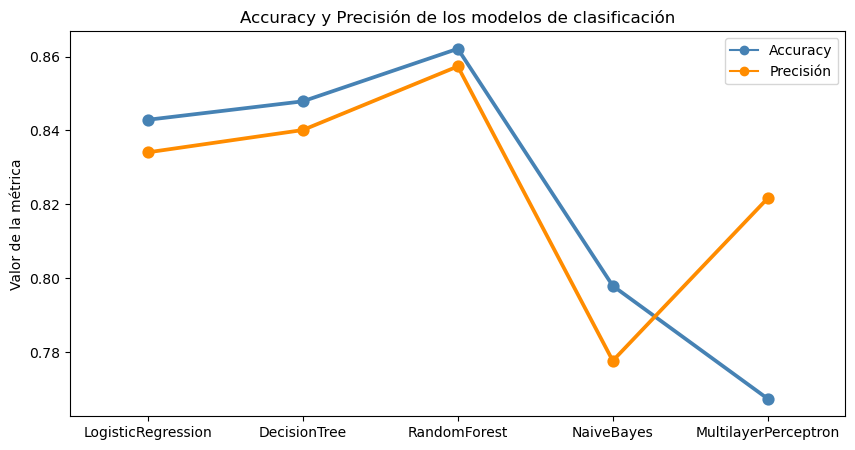

In [45]:
### Comparación de Accuracy y Precisión de los modelos usados
precissionModelos = [precisRL, precisDT, precisRF, precisNB, precisMPC]
accuracyModelos = [accuracyRL, accuracyDT, accuracyRF, accuracyNB, accuracyMPC]
modelos = ['LogisticRegression', 'DecisionTree', 'RandomForest', 'NaiveBayes', 'MultilayerPerceptron']

plt.figure(figsize = (10, 5))
plt.title("Accuracy y Precisión de los modelos de clasificación")
sns.pointplot(x = modelos, y = accuracyModelos, color = 'steelblue')
sns.pointplot(x = modelos, y = precissionModelos, color = 'darkorange')

### Leyenda para identificar cada línea
from matplotlib.lines import Line2D
plt.legend(handles = [Line2D([0], [0], color = 'steelblue', marker = 'o', label = 'Accuracy'),
                      Line2D([0], [0], color = 'darkorange', marker = 'o', label = 'Precisión')])
plt.ylabel("Valor de la métrica")
plt.show()

**Tabla comparativa de los modelos**

| Modelo | Accuracy | Precisión | Recall | >50K detectados | Falsos positivos |
|---|---|---|---|---|---|
| Regresión Logística | 84,29% | 83,41% | 84,29% | 830 de 1.557 (53,3%) | 312 |
| Árbol de Decisión | 84,79% | 84,01% | 84,79% | 799 de 1.557 (51,3%) | 248 |
| Random Forest | 86,21% | 85,73% | 86,21% | 841 de 1.557 (54,0%) | 196 |
| Naive Bayes | 79,80% | 77,77% | 79,80% | 459 de 1.557 (29,5%) | 238 |
| Perceptrón Multicapa | 76,74% | 82,17% | 76,74% | 19 de 1.557 (1,2%) | 0 |

*Referencia: un modelo que siempre prediga "<=50K" tendría 76,45% de accuracy en este conjunto de prueba.*

**Análisis comparativo**
- **Accuracy:** el mejor modelo es Random Forest (86,21%), seguido del Árbol de Decisión (84,79%) y la Regresión Logística (84,29%). Naive Bayes (79,80%) y el Perceptrón Multicapa (76,74%) quedan muy cerca del 76,45% del modelo que siempre predice "<=50K".
- **Precisión ponderada:** también la lidera Random Forest (85,73%). En la gráfica se ve que el Perceptrón Multicapa rompe la tendencia: su precisión (82,17%) queda muy por encima de su accuracy, porque las 19 predicciones de ">50K" que hizo fueron todas correctas.
- **Matrices de confusión:** Random Forest es el que más ingresos altos detecta (841) y el que menos falsos positivos tiene (196). La Regresión Logística y el Árbol de Decisión quedan cerca. Naive Bayes detecta muchos menos (459) y el Perceptrón casi ninguno (19).
- **Debilidad común:** incluso los mejores modelos dejan sin detectar alrededor del 46% de las personas con ingreso alto. Como la clase >50K es minoritaria, ante la duda los modelos tienden a predecir "<=50K".
- **Efecto del desbalance:** como la clase >50K representa el 24% de los datos, la mayoría de los modelos sí aprende a reconocer ambas clases, pero ante la duda se inclinan por la clase mayoritaria ("<=50K").

## **8. Conclusiones y recomendaciones**
### **8.1 Conclusiones**
1. **Preparación de datos (CRISP-DM):** se subió el dataset a HDFS, se renombraron y castearon las variables, se reemplazaron los datos faltantes ("?") de ClaseTrabajo, Ocupacion y PaisOrigen con la moda, y se eliminaron 24 registros duplicados. Quedaron 32.537 registros.
2. **Conocimiento de los datos:** el ingreso alto (>50K) se relaciona sobre todo con el nivel educativo, la edad (máximo entre 41 y 60 años), el estado civil y la relación familiar (personas casadas), la ocupación (cargos directivos y profesionales) y las horas trabajadas. También se observan brechas por sexo y raza, que reflejan desigualdades del censo de 1994.
3. **Desbalance:** el 24% de las personas gana más de 50K, así que un modelo que nunca prediga ingreso alto tendría ≈ 76% de accuracy. Ese es el punto de referencia para evaluar los modelos.
4. **Modelos:** se implementaron 5 modelos de MLlib con el mismo procedimiento. Random Forest fue el mejor (86,21% de accuracy, 85,73% de precisión, la mayor cantidad de ingresos altos detectados y la menor cantidad de falsos positivos), seguido del Árbol de Decisión y la Regresión Logística (≈ 84-85%). Naive Bayes y el Perceptrón Multicapa tuvieron el peor desempeño: el primero porque sus supuestos de independencia y normalidad no se cumplen, y el segundo porque las variables no están escaladas. El Perceptrón casi no superó al modelo que siempre predice "<=50K".
5. **Spark y HDFS:** todo el procesamiento se hizo de forma distribuida en el clúster del curso, leyendo los datos directamente desde HDFS. Solo se convirtió a Pandas lo necesario para graficar y construir las matrices de confusión.

### **8.2 Recomendaciones**
1. **Modelo recomendado: Random Forest.** Tuvo los mejores resultados en todas las métricas y en la matriz de confusión. Si se necesita un modelo más fácil de explicar (por ejemplo, para justificar una política pública), la Regresión Logística o el Árbol de Decisión son buenas alternativas, con solo ≈ 1,5 puntos menos de accuracy.
2. **Mejorar la detección de ingresos altos:** como la clase >50K es minoritaria (24%), se recomienda balancear las clases (por ejemplo, con pesos por clase mediante `weightCol`) o ajustar el umbral de decisión, para que los modelos detecten más personas con ingreso alto.
3. **Escalar las variables:** aplicar `StandardScaler` antes de entrenar, sobre todo para la Regresión Logística y el Perceptrón Multicapa, porque variables como PesoFinal o GananciaCapital tienen rangos muy distintos al resto.
4. **Ajustar hiperparámetros:** usar validación cruzada (`CrossValidator` + `ParamGridBuilder`) para encontrar la mejor profundidad de los árboles, la cantidad de árboles del bosque o la arquitectura del perceptrón.
5. **Revisar las variables:** evaluar si conviene eliminar PesoFinal (casi no se relaciona con el ingreso) y agrupar países o categorías con pocos registros. También se recomienda revisar el uso de Sexo y Raza como predictores: el modelo podría repetir las desigualdades del censo en sus predicciones.
6. **Validar con datos externos:** probar el modelo final con el archivo `adult.test` del mismo repositorio, que contiene 16.281 registros que el modelo nunca vio.

In [46]:
### Se cierra la sesión de Spark para liberar los recursos del clúster
sparkMortigo.stop()